# Bước 7. Kiểm tra reliability (độ tin cậy) và cách validate (kiểm chứng)

Notebook này trả lời: các con số của Bước 2 đến Bước 6 tin được đến đâu, có thể sai lệch bao nhiêu, và làm sao kiểm chứng các đề xuất ngoài thực tế.

**Đầu vào:**
- `Bước 1/shop_current.csv`, `Bước 1/shop_month.csv`; `Bước 2/shop_bau.csv`, `Bước 2/bau_params.json`; các file của Bước 4; `Bước 6/shop_priority.csv`;
- `Bước 7/xsell_theo_so_ngay.csv`: cross-sell của từng shop theo tháng với giới hạn nối lead 30 và 90 ngày, do truy vấn ở mục 7.5 tạo ra khi có file `output/r3_clean.duckdb`;
- `r3_tiem_nang.py`, `r3_bau.py`.

**Các mục:** 7.1 backtest BAU → 7.2 sai số theo quy mô shop → 7.3 nhãn độ tin cậy có tách được shop dự báo chắc hơn không → 7.4 kiểm tra giả định "thêm SA thì bán thêm" → 7.5 sensitivity test → 7.6 ví dụ quyết định thay đổi theo con số → 7.7 khoảng dao động của opportunity gap → 7.8 cách validate ngoài thực tế.

Ô dưới đây đọc dữ liệu và dựng bảng shop × tháng theo đúng các cột mà phương pháp BAU của Bước 2 dùng (hàm `panel_tu_shop_month` trong `r3_bau.py`).

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(q for q in [Path.cwd(), *Path.cwd().parents] if (q / 'Bước 1').exists())   # thư mục gốc của bài
sys.path.insert(0, str(ROOT))
from r3_tiem_nang import *
warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)   # cảnh báo đổi phiên bản của pandas, không ảnh hưởng kết quả

pd.set_option('display.width', 250); pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100); pd.set_option('display.max_colwidth', 120)
def _fmt(x):
    if x != x: return 'NaN'
    if x == int(x): return f'{x:,.0f}'
    return f'{x:,.1f}' if abs(x) >= 100 else f'{x:,.3f}'
pd.set_option('display.float_format', _fmt)

# Kiểu biểu đồ dùng chung với các bước trước: một màu chính, lưới nhạt.
BLUE, ORANGE, INK, MUTED, GREY = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#b9b8b3'
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white', 'axes.edgecolor': '#bdbcb8',
                     'axes.grid': False, 'grid.color': '#ecebe8', 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED, 'font.size': 10,
                     'lines.linewidth': 2})

import r3_bau as rb
cur = pd.read_csv(ROOT / 'Bước 1' / 'shop_current.csv', encoding='utf-8-sig')
sm = pd.read_csv(ROOT / 'Bước 1' / 'shop_month.csv', encoding='utf-8-sig')
bau = pd.read_csv(ROOT / 'Bước 2' / 'shop_bau.csv', encoding='utf-8-sig', dtype={'shop_id': str})
bau = bau[bau.shop_id != 'VIRTUAL'].assign(skp_salesroom=lambda b: b.shop_id.astype(int))
BAU = bau.set_index('skp_salesroom').bau_total_contribution_contracts
PHI = json.load(open(ROOT / 'Bước 2' / 'bau_params.json', encoding='utf-8'))['phi_by_size']
T4 = ROOT / 'Bước 4' / 'task4_output' / 'csv'
s1, s2, s3 = (pd.read_csv(T4 / f, encoding='utf-8-sig') for f in ['s1_external_checked.csv', 's2_shop_master.csv', 's3_shop_month.csv'])
pri = pd.read_csv(ROOT / 'Bước 6' / 'shop_priority.csv', encoding='utf-8-sig')
shop = cur[(cur.salesroom_status == 'Active') & (cur.shop_online == 0)][['skp_salesroom'] + G + ['salesroom_status', 'shop_online', 'shop_moi',
                                                                                              'thang_bat_dau', 'so_thang']]
phys = rb.panel_tu_shop_month(sm, shop, '2026-09-01')
print(f'Shop: {len(shop):,}; bảng shop × tháng cho backtest: {len(phys):,} dòng')

# Biểu đồ được lưu thành ảnh PNG trong thư mục Bước 7/hinh.
HINH = ROOT / 'Bước 7' / 'hinh'
HINH.mkdir(exist_ok=True)
def luu_hinh(fig, ten):
    fig.savefig(HINH / f'{ten}.png', dpi=200, bbox_inches='tight')


Shop: 11,752; bảng shop × tháng cho backtest: 246,792 dòng


## 7.1. Backtest BAU

Backtest (kiểm tra cách dự báo bằng số liệu cũ): đứng ở một tháng trong quá khứ, chỉ dùng dữ liệu đến tháng đó, dự báo 6 tháng sau bằng đúng cách của Bước 2 (hàm `run_backtest` chép nguyên văn từ Bước 2), rồi so với số thật. Có hai mốc: 12/2025 (dự báo 01–06/2026) và 03/2026 (dự báo 04–09/2026). Mỗi mốc so ba cách dự báo:
- BAU theo cách của Bước 2;
- trung bình 3 tháng trước: cách đơn giản nhất, tháng tới bằng trung bình 3 tháng gần nhất;
- kéo dài trend thô 6 tháng: kẻ đường thẳng qua 6 tháng gần nhất rồi kéo dài.

Hai thước đo, tính trên tổng 6 tháng của từng shop:
- WAPE = tổng sai lệch tuyệt đối của các shop / tổng thực tế. Ví dụ shop A dự báo 10, thật 8; shop B dự báo 5, thật 7: WAPE = (2 + 2) / 15 ≈ 0,27;
- Bias = tổng dự báo / tổng thực tế − 1: dương là dự báo cao hơn thật, âm là thấp hơn thật.

In [2]:
ket_qua = {}
for goc in ['2025-12-01', '2026-03-01']:
    bt = rb.run_backtest(phys, pd.Timestamp(goc))
    ket_qua[goc] = bt
    A = bt.actual
    rows = []
    for cot, ten in [('BAU', 'BAU (cách của Bước 2)'), ('NAIVE3', 'trung bình 3 tháng trước'), ('RAW_TREND', 'kéo dài trend thô 6 tháng')]:
        rows.append({'cach_du_bao': ten, 'WAPE': (bt[cot] - A).abs().sum() / A.sum(), 'Bias': bt[cot].sum() / A.sum() - 1})
    print(f"Đứng ở {goc[:7]}: {len(bt):,} shop, dự báo 6 tháng sau; κ = {bt.attrs['kappa']:.3f}; tổng thực tế {A.sum():,.0f} contract")
    display(pd.DataFrame(rows).set_index('cach_du_bao'))

Đứng ở 2025-12: 4,086 shop, dự báo 6 tháng sau; κ = 0.347; tổng thực tế 95,747 contract


,WAPE,Bias
cach_du_bao,,
BAU (cách của Bước 2),0.460,-0.089
trung bình 3 tháng trước,0.474,-0.028
kéo dài trend thô 6 tháng,1.061,0.472


Đứng ở 2026-03: 5,496 shop, dự báo 6 tháng sau; κ = 0.306; tổng thực tế 131,495 contract


,WAPE,Bias
cach_du_bao,,
BAU (cách của Bước 2),0.460,-0.006
trung bình 3 tháng trước,0.475,0.023
kéo dài trend thô 6 tháng,0.977,0.491


- Ở cả hai mốc, BAU của Bước 2 có WAPE thấp nhất (0,460), thấp hơn cách trung bình 3 tháng trước (0,474 và 0,475) khoảng 3%. Kéo dài trend thô sai gấp đôi (0,977–1,061) và dự báo cao hơn thật gần 50%.
- Về tổng, BAU thấp hơn thật 8,9% ở mốc 12/2025 và 0,6% ở mốc 03/2026; cách trung bình 3 tháng lệch −2,8% và +2,3%. Không cách nào luôn sát tổng hơn.
- Kết luận: cách của Bước 2 sai ít hơn cách đơn giản ở từng shop, nhưng chỉ ít hơn một chút. BAU của Bước 2 vẫn được giữ, vì nó tính đến việc shop mới giảm dần sau những tháng đầu, điều mà cách trung bình 3 tháng không có. Khi trình bày cho ban quản lý, có thể nói BAU gần bằng trung bình 3 tháng gần nhất, có điều chỉnh cho shop mới.
- Với WAPE khoảng 0,46, dự báo của một shop thường lệch gần một nửa so với thật, nên BAU của từng shop chỉ là mức tham khảo; tổng của nhiều shop sát thật hơn nhiều.

## 7.2. Sai số theo quy mô shop

Ô dưới đây chia sai số ở mốc 03/2026 theo quy mô shop (số contract bán trực tiếp trung bình mỗi tháng của 01–03/2026). Cột `WAPE_TB3`, `Bias_TB3` là của cách trung bình 3 tháng trước.

In [3]:
bt = ket_qua['2026-03-01'].copy()
muc = phys[(phys.month >= '2026-01-01') & (phys.month <= '2026-03-01')].groupby('shop_id').signed_contracts.mean()
bt['quy_mo'] = pd.cut(muc.reindex(bt.index).fillna(0), [-0.1, 1, 3, 10, np.inf], labels=['dưới 1', '1–3', '3–10', 'từ 10'])
def tinh(g):
    A = g.actual
    return pd.Series({'so_shop': len(g), 'thuc_te': A.sum(), 'WAPE_BAU': (g.BAU - A).abs().sum() / A.sum(),
                      'WAPE_TB3': (g.NAIVE3 - A).abs().sum() / A.sum(), 'Bias_BAU': g.BAU.sum() / A.sum() - 1, 'Bias_TB3': g.NAIVE3.sum() / A.sum() - 1})
bt.groupby('quy_mo', observed=True).apply(tinh)

,so_shop,thuc_te,WAPE_BAU,WAPE_TB3,Bias_BAU,Bias_TB3
quy_mo,,,,,,
dưới 1,"2,603","12,899",0.801,0.816,-0.456,-0.535
1–3,"1,241","16,671",0.576,0.595,-0.107,-0.065
3–10,"1,093","36,539",0.463,0.488,0.010,0.043
từ 10,559,"65,386",0.362,0.371,0.100,0.145


- Sai số giảm rõ khi shop bán nhiều hơn: WAPE 0,801 ở shop bán dưới 1 contract mỗi tháng, 0,576 ở shop 1–3, 0,463 ở shop 3–10, và 0,362 ở shop từ 10 contract.
- Với shop bán dưới 1 contract mỗi tháng, tổng thực tế cao hơn dự báo rất nhiều (Bias −45,6%), vì một số shop gần như không bán trước đó lại bán được ở các tháng sau.
- Đây là bằng chứng cho điều kiện "bán dưới 3 contract mỗi tháng" trong nhãn độ tin cậy của Bước 6.

## 7.3. Nhãn độ tin cậy có tách được shop dự báo chắc hơn không

Ô dưới đây đứng ở 03/2026, gắn nhãn độ tin cậy theo đúng quy tắc của Bước 6 nhưng chỉ dùng dữ liệu đến 03/2026 (Current Actual là trung bình 01–03/2026, rủi ro đo trên contract nộp hồ sơ đến 11/2025), rồi tính sai số của dự báo 04–09/2026 theo nhãn.

In [4]:
shop3 = shop[pd.to_datetime(shop.thang_bat_dau) <= '2026-03-01'].copy()
bd3 = pd.to_datetime(shop3.thang_bat_dau)
shop3['shop_moi'] = (((2026 - bd3.dt.year) * 12 + 3 - bd3.dt.month + 1) < 6).astype(int)
sm3 = sm[sm.thang <= '2026-03-01']
b3_, _ = rb.bau_tai(rb.panel_tu_shop_month(sm3, shop3, '2026-03-01'), '2026-03-01')
xs3 = sm3[sm3.thang >= '2026-01-01'].groupby('skp_salesroom').xsell_hd.sum() / 3
s03 = chay_lai(shop3, sm3, s1, s2, s3, b3_.bau.set_axis(b3_.index.astype(int)).add(xs3, fill_value=0), '2026-01-01', '2026-03-01', PHI,
               rr_den='2025-11-01')
bt['do_tin_cay'] = bt.index.astype(int).map(s03.set_index('skp_salesroom').do_tin_cay)
bt.groupby('do_tin_cay').apply(tinh)

,so_shop,thuc_te,WAPE_BAU,WAPE_TB3,Bias_BAU,Bias_TB3
do_tin_cay,,,,,,
cao,731,"36,081",0.399,0.402,0.149,0.132
không tính được,803,"1,554",1.076,1,-0.511,-1
thấp,"3,962","93,860",0.473,0.495,-0.057,-0.002


- Shop có nhãn cao có WAPE 0,399, thấp hơn shop có nhãn thấp (0,473). Shop không tính được (không có hồ sơ trong quý) có WAPE 1,076, tức gần như không dự báo được.
- Nhãn tách được shop có dự báo chắc hơn, nhưng khoảng cách không lớn: ngay cả ở shop có nhãn cao, dự báo của một shop vẫn lệch khoảng 40%.
- Ở shop có nhãn cao, BAU cao hơn thật 14,9%. Nếu điều này lặp lại, BAU của nhóm Đầu tư ngay đang cao hơn mức shop thật sự đạt khi để yên, nên gap của nhóm này (Attainable Potential − BAU) có thể đang bị tính thấp hơn thật.

## 7.4. Kiểm tra giả định "thêm SA thì bán thêm"

Bước 3 giả định nếu shop có thêm SA đến mức benchmark thì shop ký thêm contract theo năng suất hiện tại của SA. Ô dưới đây kiểm tra giả định này bằng các trường hợp đã xảy ra trong 2025–2026:
- nhóm thêm SA: shop có đúng 1 SA làm hồ sơ trong 3 tháng liền, rồi có từ 2 SA trong 3 tháng liền ngay sau đó;
- nhóm giữ 1 SA: shop có đúng 1 SA trong cả 6 tháng đó, làm mốc so sánh cho cùng các tháng.

So số contract bán trực tiếp trung bình mỗi tháng của 3 tháng trước và 3 tháng sau. Cách so này là difference-in-differences (so chênh lệch của chênh lệch): lấy mức tăng của nhóm thêm SA trừ mức tăng của nhóm giữ 1 SA, để bỏ phần tăng chung của mọi shop trong cùng giai đoạn (ví dụ do mùa vụ). Một shop có thể có nhiều lần, ứng với các tháng đổi khác nhau (cột `so_lan`). Cột `thang_truoc_3` và `thang_truoc_1` là số contract ở tháng thứ 3 và tháng thứ 1 trước khi đổi số SA.

In [5]:
x = sm[['skp_salesroom', 'thang', 'so_sa', 'hd_ky', 'ho_so']].copy()
x['thang'] = pd.to_datetime(x.thang)
x = x.merge(cur[['skp_salesroom', 'salesroom_product', 'salesroom_model']], on='skp_salesroom')
w = x.pivot_table(index='skp_salesroom', columns='thang', values=['so_sa', 'hd_ky'], fill_value=0)
thang = sorted(x.thang.unique())
rows = []
for i in range(3, len(thang) - 2):
    truoc, sau = thang[i - 3:i], thang[i:i + 3]
    sa_t, sa_s = w['so_sa'][truoc], w['so_sa'][sau]
    hd_t, hd_s = w['hd_ky'][truoc].mean(axis=1), w['hd_ky'][sau].mean(axis=1)
    them = (sa_t == 1).all(axis=1) & (sa_s >= 2).all(axis=1)
    giu = (sa_t == 1).all(axis=1) & (sa_s == 1).all(axis=1)
    for nhom, v in [('thêm SA', them), ('giữ 1 SA', giu)]:
        rows.append(pd.DataFrame({'skp_salesroom': v[v].index, 'thang_doi': thang[i], 'nhom': nhom,
                                  'hd_truoc': hd_t[v].to_numpy(), 'hd_sau': hd_s[v].to_numpy(), 'sa_sau': sa_s[v].mean(axis=1).to_numpy(),
                                  'hd_thang_truoc_3': w['hd_ky'][thang[i - 3]][v].to_numpy(), 'hd_thang_truoc_1': w['hd_ky'][thang[i - 1]][v].to_numpy()}))
ev = pd.concat(rows, ignore_index=True)
t = ev.groupby('nhom').agg(so_lan=('skp_salesroom', 'size'), so_shop=('skp_salesroom', 'nunique'), hd_truoc=('hd_truoc', 'mean'),
                           hd_sau=('hd_sau', 'mean'), sa_sau=('sa_sau', 'mean'), thang_truoc_3=('hd_thang_truoc_3', 'mean'),
                           thang_truoc_1=('hd_thang_truoc_1', 'mean'))
t['tang'] = t.hd_sau - t.hd_truoc
t['hd_moi_sa_sau'] = t.hd_sau / t.sa_sau
display(t)
did = t.loc['thêm SA', 'tang'] - t.loc['giữ 1 SA', 'tang']
print(f"Chênh lệch giữa hai nhóm (difference-in-differences): {did:+.2f} contract mỗi tháng; "
      f"so với mức trước của nhóm thêm SA: {did / t.loc['thêm SA', 'hd_truoc']:+.0%}")

,so_lan,so_shop,hd_truoc,hd_sau,sa_sau,thang_truoc_3,thang_truoc_1,tang,hd_moi_sa_sau
nhom,,,,,,,,,
giữ 1 SA,4833,1412,4.532,4.635,1,4.348,4.619,0.102,4.635
thêm SA,236,234,6.195,9.651,2.295,5.314,7.212,3.456,4.205


Chênh lệch giữa hai nhóm (difference-in-differences): +3.35 contract mỗi tháng; so với mức trước của nhóm thêm SA: +54%


- Có 236 lần thêm SA ở 234 shop; sau đó shop có trung bình 2,3 SA. Doanh số tăng từ 6,2 lên 9,7 contract mỗi tháng (+3,46), trong khi nhóm giữ 1 SA chỉ tăng 0,10. Chênh lệch là +3,35 contract mỗi tháng, tức +54% so với mức trước.
- Mỗi SA ở nhóm thêm SA vẫn ký 4,2 contract mỗi tháng, gần bằng 4,6 của shop có 1 SA: SA thêm vào không chỉ chia nhau lượng khách cũ mà tạo thêm contract.
- Nhưng doanh số của nhóm thêm SA đã tăng trước khi có thêm SA: từ 5,3 (tháng trước 3) lên 7,2 (tháng trước 1). Có thể shop đông khách lên trước, rồi mới cần thêm người làm hồ sơ. Khi đó một phần mức tăng không phải do thêm SA.

Ô dưới đây tính khoảng tin cậy 95% của mức tăng (so mỗi lần thêm SA với mức tăng trung bình của nhóm giữ 1 SA cùng tháng), rồi tính lại chỉ với những lần đổi mà doanh số không tăng trong 3 tháng trước, để bỏ trường hợp shop đông khách lên trước.

In [6]:
from scipy import stats
th = ev[ev.nhom == 'thêm SA']
gi = ev[ev.nhom == 'giữ 1 SA']
moc = gi.groupby('thang_doi').apply(lambda g: (g.hd_sau - g.hd_truoc).mean())
th = th.assign(tang_rieng=(th.hd_sau - th.hd_truoc) - th.thang_doi.map(moc))
ci = stats.t.interval(0.95, len(th) - 1, loc=th.tang_rieng.mean(), scale=th.tang_rieng.std() / np.sqrt(len(th)))
print(f"Mức tăng của nhóm thêm SA so với nhóm giữ 1 SA cùng tháng: trung bình {th.tang_rieng.mean():+.2f} contract/tháng, "
      f"khoảng tin cậy 95%: {ci[0]:+.2f} đến {ci[1]:+.2f}")
pt = ev.assign(tang_truoc=ev.hd_thang_truoc_1 - ev.hd_thang_truoc_3).groupby('nhom').tang_truoc.mean()
print(f"Trước khi đổi số SA (tháng trước 1 so với tháng trước 3): nhóm thêm SA {pt['thêm SA']:+.2f}, nhóm giữ 1 SA {pt['giữ 1 SA']:+.2f} contract")
e2 = ev[ev.hd_thang_truoc_1 <= ev.hd_thang_truoc_3]
t2 = e2.groupby('nhom').agg(so_lan=('skp_salesroom', 'size'), hd_truoc=('hd_truoc', 'mean'), hd_sau=('hd_sau', 'mean'), sa_sau=('sa_sau', 'mean'),
                            tang_truoc=('hd_thang_truoc_1', 'mean'))
t2['tang_truoc'] = e2.assign(v=e2.hd_thang_truoc_1 - e2.hd_thang_truoc_3).groupby('nhom').v.mean()
t2['tang'] = t2.hd_sau - t2.hd_truoc
display(t2)
did2 = t2.loc['thêm SA', 'tang'] - t2.loc['giữ 1 SA', 'tang']
print(f"Chỉ xét lần đổi mà doanh số không tăng trong 3 tháng trước: chênh lệch {did2:+.2f} contract mỗi tháng, "
      f"tức khoảng {did2 / (t2.loc['thêm SA', 'sa_sau'] - 1):.2f} contract cho mỗi SA thêm")

Mức tăng của nhóm thêm SA so với nhóm giữ 1 SA cùng tháng: trung bình +3.35 contract/tháng, khoảng tin cậy 95%: +2.57 đến +4.14
Trước khi đổi số SA (tháng trước 1 so với tháng trước 3): nhóm thêm SA +1.90, nhóm giữ 1 SA +0.27 contract


,so_lan,hd_truoc,hd_sau,sa_sau,tang_truoc,tang
nhom,,,,,,
giữ 1 SA,2675,4.257,4.170,1,-2.536,-0.086
thêm SA,100,5.870,8.513,2.270,-2.620,2.643


Chỉ xét lần đổi mà doanh số không tăng trong 3 tháng trước: chênh lệch +2.73 contract mỗi tháng, tức khoảng 2.15 contract cho mỗi SA thêm


- Mức tăng so với shop giữ 1 SA cùng tháng là +3,35 contract mỗi tháng, khoảng tin cậy 95% từ +2,57 đến +4,14: mức tăng chắc chắn lớn hơn 0.
- Chỉ xét 100 lần đổi mà doanh số không tăng trong 3 tháng trước (mức thay đổi trước của hai nhóm gần bằng nhau: −2,62 và −2,54), chênh lệch vẫn là +2,73 contract mỗi tháng, khoảng 2,15 contract cho mỗi SA thêm.
- Con số này cao hơn mức 1,83 contract cho mỗi SA thêm mà Bước 6 (mục 6.7) tính từ Attainable Potential. Giả định "thêm SA thì bán thêm" có bằng chứng trong dữ liệu, và mức Bước 3 dùng không quá lạc quan.
- Đây vẫn chưa phải bằng chứng chắc chắn, vì công ty không chủ động chọn shop để thêm SA: shop có thêm SA có thể là shop mà chủ shop đang muốn đẩy bán. Vì vậy vẫn cần pilot có nhóm đối chứng (mục 7.8).

## 7.5. Sensitivity test

Sensitivity test (thử đổi giả định xem kết quả có đổi nhiều không): đổi từng giả định, chạy lại Bước 3 đến Bước 6 bằng hàm `chay_lai`, rồi đo danh sách shop ưu tiên thay đổi bao nhiêu. Các giả định được đổi:
- benchmark là mức mà top 25% shop cùng loại đạt được, đổi thành top 20% (mức 80%) hoặc top 33% (mức 67%);
- giới hạn ngày nối lead với contract đổi từ 30 thành 90 ngày;
- Current Actual tính trên 3 tháng (07–09/2026) đổi thành 6 tháng (04–09/2026); trần thị trường cũng đo trên cùng 6 tháng.

BAU của Bước 2 giữ nguyên ở mọi trường hợp, vì BAU là dự báo, không phụ thuộc các giả định này.

Để đổi giới hạn ngày nối lead, ô dưới đây đếm lại cross-sell của từng shop theo tháng với hai giới hạn 30 và 90 ngày, theo đúng cách nối lead của Bước 1 (cùng khách, cùng sản phẩm, lead giao trước hoặc cùng lúc nộp hồ sơ, mỗi contract chỉ ghi công cho lead gần nhất). Truy vấn chạy trên file `output/r3_clean.duckdb`; nếu không có file này, ô đọc lại kết quả đã lưu ở `Bước 7/xsell_theo_so_ngay.csv`. Dòng kiểm tra so con số 30 ngày với Bước 1.

In [7]:
xs_file = ROOT / 'Bước 7' / 'xsell_theo_so_ngay.csv'
db_file = ROOT / 'output' / 'r3_clean.duckdb'
if db_file.exists():
    from r3_db import connect
    con = connect()
    xs = con.execute('''
    with l as (select row_number() over (order by id_uuid, date_assigned, skp_salesroom, code_product_type_original, id_lead_source) lead_id,
                 skp_salesroom shop_lead, skp_client, code_product_type sp, date_assigned
               from leads where code_product_type in ('CL','CC','TW','CD')),
    k as (select skp_credit_case, skp_salesroom shop_hd, skp_client, product sp, date_apply, apply_month, is_signed
          from contract where product in ('CL','CC','TW','CD')),
    cap as (select l.shop_lead, k.shop_hd, k.apply_month, k.is_signed, date_diff('day', l.date_assigned, k.date_apply) so_ngay,
              row_number() over (partition by k.skp_credit_case order by l.date_assigned desc, l.lead_id) thu_tu
            from l join k on l.skp_client=k.skp_client and l.sp=k.sp and k.date_apply>=l.date_assigned)
    select shop_lead skp_salesroom, apply_month thang,
      count(*) filter (where so_ngay<=30) xsell_30, count(*) filter (where so_ngay<=90) xsell_90
    from cap where thu_tu=1 and is_signed=1 and shop_hd is distinct from shop_lead
      and shop_lead in (select skp_salesroom from salesroom)
    group by all order by 1,2''').df()
    xs.to_csv(xs_file, index=False, encoding='utf-8-sig')
else:
    xs = pd.read_csv(xs_file, encoding='utf-8-sig')
xs['thang'] = pd.to_datetime(xs.thang).dt.strftime('%Y-%m-%d')
kt = sm[['skp_salesroom', 'thang', 'xsell_hd']].merge(xs, on=['skp_salesroom', 'thang'], how='outer').fillna(0)
print(f"Kiểm tra với Bước 1 (30 ngày): lệch lớn nhất {(kt.xsell_hd - kt.xsell_30).abs().max():.0f}; "
      f"tổng cross-sell 30 ngày {xs.xsell_30.sum():,}, 90 ngày {xs.xsell_90.sum():,}")
xs90 = xs[['skp_salesroom', 'thang', 'xsell_90']].rename(columns={'xsell_90': 'xsell_hd'})

Kiểm tra với Bước 1 (30 ngày): lệch lớn nhất 0; tổng cross-sell 30 ngày 9,609, 90 ngày 11,096


Con số 30 ngày khớp hoàn toàn với Bước 1. Nới lên 90 ngày, cross-sell tăng từ 9.609 lên 11.096 contract trong cả giai đoạn (+15,5%).

Ô dưới đây chạy 5 trường hợp. Các cột:
- `current_actual`, `attainable`, `gap`: tổng của toàn mạng lưới, contract mỗi tháng;
- `shop_dau_tu_ngay`, `giu_lai_dau_tu_ngay`: số shop Đầu tư ngay, và tỷ lệ shop Đầu tư ngay của trường hợp cơ sở vẫn ở nhóm này;
- `shop_gap_lon`, `giu_lai_gap_lon`: tương tự cho các shop có gap từ 2 contract mỗi tháng (Đầu tư ngay cộng Pilot);
- `shop_doi_nhom`: tỷ lệ shop đổi nhóm so với trường hợp cơ sở.

Kiểm tra cơ sở so với Bước 6: shop khác nhóm = 0


,current_actual,attainable,gap,shop_dau_tu_ngay,giu_lai_dau_tu_ngay,shop_gap_lon,giu_lai_gap_lon,shop_doi_nhom
gia_dinh,,,,,,,,
"Cơ sở (top 25%, 30 ngày, 3 tháng)","39,450","55,595.3","16,323.6",184,1,3099,1,0
Benchmark top 20%,"39,450","59,897.3","20,625.7",287,0.995,3910,0.997,0.071
Benchmark top 33%,"39,450","51,326.6","12,055.0",95,0.495,1898,0.611,0.103
Nối lead trong 90 ngày,"39,690.7","55,760.7","16,489.1",199,1,3125,0.996,0.004
Current Actual trên 6 tháng (04–09/2026),"34,378.8","51,164.0","11,892.4",141,0.190,2055,0.467,0.194


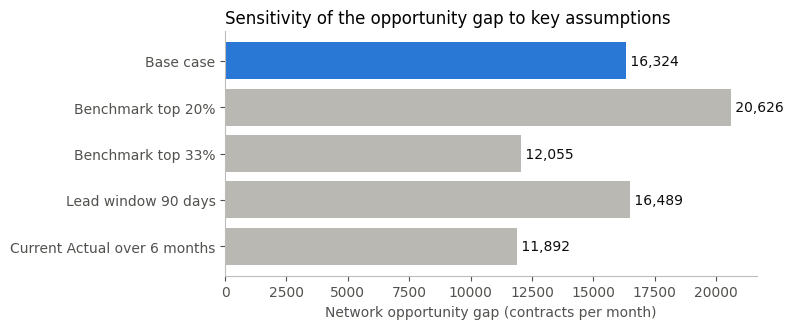

In [8]:
KB = {'Cơ sở (top 25%, 30 ngày, 3 tháng)': dict(),
      'Benchmark top 20%': dict(muc=0.80),
      'Benchmark top 33%': dict(muc=0.67),
      'Nối lead trong 90 ngày': dict(xsell=xs90),
      'Current Actual trên 6 tháng (04–09/2026)': dict(thang_tu='2026-04-01')}
kq = {}
for ten, gs in KB.items():
    tu = gs.pop('thang_tu', '2026-07-01')
    kq[ten] = chay_lai(shop, sm, s1, s2, s3, BAU, tu, '2026-09-01', PHI, **gs).set_index('skp_salesroom')
co_so = kq['Cơ sở (top 25%, 30 ngày, 3 tháng)']
print('Kiểm tra cơ sở so với Bước 6: shop khác nhóm =', int((co_so.nhom != pri.set_index('skp_salesroom').nhom.reindex(co_so.index)).sum()))
rows = []
for ten, k in kq.items():
    uu_cs = set(co_so.index[co_so.nhom == 'Đầu tư ngay']); uu = set(k.index[k.nhom == 'Đầu tư ngay'])
    rg_cs = set(co_so.index[co_so.nhom.isin(['Đầu tư ngay', 'Pilot'])]); rg = set(k.index[k.nhom.isin(['Đầu tư ngay', 'Pilot'])])
    rows.append({'gia_dinh': ten, 'current_actual': k.ca_hd_tong.sum(), 'attainable': k.ap.sum(), 'gap': k.gap.sum(),
                 'shop_dau_tu_ngay': len(uu), 'giu_lai_dau_tu_ngay': len(uu & uu_cs) / len(uu_cs),
                 'shop_gap_lon': len(rg), 'giu_lai_gap_lon': len(rg & rg_cs) / len(rg_cs),
                 'shop_doi_nhom': (k.nhom != co_so.nhom.reindex(k.index)).mean()})
nhay = pd.DataFrame(rows).set_index('gia_dinh')
display(nhay)
EN = ['Base case', 'Benchmark top 20%', 'Benchmark top 33%', 'Lead window 90 days', 'Current Actual over 6 months']
fig, ax = plt.subplots(figsize=(8, 3.4)); ax.set_axisbelow(True)
ax.barh(EN[::-1], nhay.gap.to_numpy()[::-1], color=[GREY] * 4 + [BLUE])
for i, v_ in enumerate(nhay.gap.to_numpy()[::-1]):
    ax.text(v_, i, f' {v_:,.0f}', va='center', color=INK)
ax.set_xlabel('Network opportunity gap (contracts per month)'); ax.set_title('Sensitivity of the opportunity gap to key assumptions', loc='left')
plt.tight_layout(); luu_hinh(fig, 'b7_01_sensitivity'); plt.show()


- Nối lead trong 90 ngày gần như không đổi gì: gap tăng 1,0% (16.489,1 so với 16.323,6), chỉ 0,4% shop đổi nhóm. Kết luận không phụ thuộc giới hạn ngày nối lead.
- Benchmark top 20%: gap tăng lên 20.625,7 (+26%); nhóm Đầu tư ngay tăng lên 287 shop và vẫn giữ 99,5% shop cũ; 7,1% shop đổi nhóm. Danh sách cũ vẫn đúng, chỉ có thêm shop.
- Benchmark top 33%: gap giảm còn 12.055,0 (−26%); chỉ 49,5% shop Đầu tư ngay và 61,1% shop có gap lớn còn giữ nhóm; 10,3% shop đổi nhóm. Nhóm Đầu tư ngay nhạy với mức benchmark vì nhiều shop có gap chỉ hơi trên ngưỡng 2 contract.
- Current Actual trên 6 tháng: Current Actual giảm còn 34.378,8 vì mạng lưới đang lớn dần (quý 2 bán ít hơn quý 3); gap còn 11.892,4; chỉ 19,0% shop Đầu tư ngay và 46,7% shop có gap lớn còn giữ nhóm; 19,4% shop đổi nhóm. Đây là giả định làm danh sách đổi nhiều nhất.
- Cần nói rõ khi trình bày: tổng gap và danh sách shop có gap lớn không đổi theo giới hạn nối lead và giữ nguyên khi benchmark cao hơn, nhưng nhạy với benchmark thấp hơn và với cửa sổ đo Current Actual. Nhóm Đầu tư ngay là phần nhạy nhất. Điều này khớp với kết quả ổn định ở Bước 6 (mục 6.6), và là lý do lộ trình chỉ thêm SA sau pilot.

## 7.6. Ví dụ quyết định thay đổi theo con số

Ô dưới đây lấy shop Đầu tư ngay có gap giảm nhiều nhất khi đổi benchmark từ top 25% sang top 33%, và in 4 con số, nhóm và hành động của shop ở hai giả định.

In [9]:
k33 = kq['Benchmark top 33%']
doi = co_so.join(k33[['gap', 'nhom', 'ap']], rsuffix='_33')
ung = doi[(doi.nhom == 'Đầu tư ngay') & (doi.nhom_33 != 'Đầu tư ngay')]
vd = ung.loc[(ung.gap - ung.gap_33).idxmax()]
print(f"Shop {vd.name}: {vd.salesroom_category} · {vd.salesroom_product} · {vd.salesroom_model} · {vd.salesroom_province}; "
      f"Current Actual {vd.ca_hd_tong:.2f}, BAU {vd.bau:.2f} contract/tháng")
print(f"   Benchmark top 25%: Attainable Potential {vd.ap:.2f}, gap {vd.gap:.2f} → nhóm {vd.nhom}; hành động: {pri.set_index('skp_salesroom').hanh_dong.get(vd.name)}")
print(f"   Benchmark top 33%: Attainable Potential {vd.ap_33:.2f}, gap {vd.gap_33:.2f} → nhóm {vd.nhom_33}")
print(f"   Số SA {vd.ca_so_sa:.2f} (benchmark top 25%: {vd.bm_so_sa:.2f}, top 33%: {k33.loc[vd.name, 'bm_so_sa']:.2f}); "
      f"hồ sơ mỗi SA {vd.ca_ho_so_moi_sa:.2f} (benchmark top 25%: {vd.bm_ho_so_moi_sa:.2f}, top 33%: {k33.loc[vd.name, 'bm_ho_so_moi_sa']:.2f})")
print(f"Shop Đầu tư ngay chuyển nhóm khi đổi sang top 33%: {len(ung)}; sang nhóm: {ung.nhom_33.value_counts().to_dict()}")

Shop 95827555: Small · TW · Non-Aldi · TP. Đồng Nai; Current Actual 4.67, BAU 4.55 contract/tháng
   Benchmark top 25%: Attainable Potential 10.31, gap 5.76 → nhóm Đầu tư ngay; hành động: Thêm SA cho shop đến mức benchmark của peer group
   Benchmark top 33%: Attainable Potential 6.53, gap 1.97 → nhóm Giữ nguyên
   Số SA 1.33 (benchmark top 25%: 2.17, top 33%: 2.00); hồ sơ mỗi SA 3.75 (benchmark top 25%: 5.35, top 33%: 4.54)
Shop Đầu tư ngay chuyển nhóm khi đổi sang top 33%: 93; sang nhóm: {'Giữ nguyên': 93}


Shop 95827555 là shop xe máy (TW) Small, kiểu Non-Aldi ở Đồng Nai, đang ký 4,67 contract mỗi tháng, BAU 4,55.
- Với benchmark top 25%: shop có 1,33 SA, so với 2,17 của benchmark, và mỗi SA làm 3,75 hồ sơ mỗi tháng, so với 5,35. Attainable Potential là 10,31, gap 5,76 contract mỗi tháng, nên shop thuộc nhóm Đầu tư ngay, hành động là thêm SA.
- Với benchmark top 33%: benchmark giảm còn 2,00 SA và 4,54 hồ sơ mỗi SA. Attainable Potential còn 6,53, gap 1,97, ngay dưới ngưỡng 2, nên shop chuyển sang Giữ nguyên và không được đầu tư thêm.
- Khi đổi sang top 33%, 93 shop Đầu tư ngay chuyển nhóm, tất cả sang Giữ nguyên.

Với các shop gần ngưỡng như shop này, quyết định đầu tư phụ thuộc vào mức benchmark. Ở cả hai giả định, shop vẫn thiếu SA và SA vẫn làm ít hồ sơ hơn benchmark (3,75 so với 4,54), nên hành động rẻ như đào tạo SA vẫn hợp lý; hành động tốn kém như thêm SA thì chờ kết quả pilot.

## 7.7. Khoảng dao động của opportunity gap

Ô dưới đây lấy mức thấp nhất và cao nhất của tổng opportunity gap trong 5 trường hợp ở mục 7.5, và so với BAU của toàn mạng lưới.

In [10]:
pd.DataFrame({'gap_thap_nhat': [nhay.gap.min()], 'gap_co_so': [nhay.gap.iloc[0]], 'gap_cao_nhat': [nhay.gap.max()],
              'so_voi_bau_thap_nhat': [nhay.gap.min() / BAU.sum()], 'so_voi_bau_cao_nhat': [nhay.gap.max() / BAU.sum()]},
             index=['opportunity gap (contract/tháng)'])

,gap_thap_nhat,gap_co_so,gap_cao_nhat,so_voi_bau_thap_nhat,so_voi_bau_cao_nhat
opportunity gap (contract/tháng),"11,892.4","16,323.6","20,625.7",0.303,0.525


Tổng opportunity gap nằm trong khoảng 11.892 đến 20.626 contract mỗi tháng, tức 30,3% đến 52,5% BAU, với mức cơ sở 16.324 (41,6%). Khi trình bày, nên nói gap vào khoảng 12–21 nghìn contract mỗi tháng, mức cơ sở khoảng 16 nghìn.

## 7.8. Cách validate ngoài thực tế

Các kiểm tra ở trên đều dùng dữ liệu quá khứ, trong đó công ty không chủ động chọn shop để can thiệp. Để biết đề xuất có đúng không, cần một thử nghiệm có nhóm đối chứng, theo lộ trình ở Bước 6:
1. **Chọn shop:** trong 2.562 shop Pilot có nguyên nhân chính là staffing hoặc năng suất SA (Bước 6 mục 6.8), chọn ngẫu nhiên 96 shop rồi chia ngẫu nhiên thành 48 shop làm thử và 48 shop đối chứng, sao cho hai nhóm có cùng số shop theo vùng và theo nguyên nhân chính. Chọn ngẫu nhiên để hai nhóm giống nhau ở mọi mặt, kể cả những mặt dữ liệu không đo được như chủ shop có muốn đẩy bán hay không, điều mà mục 7.4 chưa loại được.
2. **Can thiệp:** shop làm thử có nguyên nhân staffing được thêm SA hoặc bố trí SA làm hồ sơ đều mọi tháng; shop làm thử có nguyên nhân năng suất được đào tạo, kèm cặp SA. Control group (nhóm đối chứng) giữ nguyên, không thêm SA, không đào tạo.
3. **Thời gian:** 3 tháng (11/2026 – 01/2027). Số contract của cả hai nhóm trong 3 tháng trước khi bắt đầu được dùng làm mốc.
4. **Đo:** mức thay đổi số contract mỗi tháng (3 tháng sau trừ 3 tháng trước) của từng shop, so hai nhóm bằng difference-in-differences như mục 7.4. Đo thêm hồ sơ mỗi SA, contract mỗi SA, và tỷ lệ contract có khách trễ hạn trong 4 kỳ đầu khi các contract đã qua 4 kỳ trả.
5. **Quyết định:** nếu nhóm làm thử tăng nhiều hơn nhóm đối chứng, khoảng tin cậy 95% của chênh lệch không chứa 0, và tỷ lệ trễ hạn không cao hơn nhóm đối chứng, thì đề xuất là đúng và được mở rộng (Bước 6, giai đoạn 2). Với 48 shop mỗi nhóm, thử nghiệm đủ để phát hiện mức tăng bằng 50% gap (khoảng 2 contract mỗi tháng), theo power analysis ở Bước 6. Nếu chênh lệch nhỏ hơn, không mở rộng việc thêm SA mà chỉ giữ các hành động rẻ.
6. **Theo dõi toàn mạng lưới:** mỗi tháng so số contract thật với BAU của từng nhóm shop. Nhóm Giữ nguyên là mốc: nếu nhóm này bán đúng như BAU còn các nhóm được đầu tư bán cao hơn BAU, phần chênh là kết quả của can thiệp.

## 7.9. Tóm tắt

- BAU của Bước 2 có sai số theo từng shop thấp hơn cách đơn giản "trung bình 3 tháng trước" ở cả hai mốc backtest (WAPE 0,460 so với 0,474–0,475), nhưng chỉ thấp hơn một chút. Sai số lớn ở shop bán ít (0,801 ở shop dưới 1 contract mỗi tháng) và nhỏ ở shop bán nhiều (0,362).
- Nhãn độ tin cậy của Bước 6 tách được shop có dự báo chắc hơn (WAPE 0,399 ở nhãn cao so với 0,473 ở nhãn thấp).
- Giả định "thêm SA thì bán thêm" có bằng chứng: shop từ 1 lên khoảng 2 SA ký thêm 2,73–3,35 contract mỗi tháng so với shop giữ 1 SA, khoảng 2,15 contract cho mỗi SA thêm, cao hơn mức 1,83 mà Bước 6 dùng.
- Kết luận không đổi khi nối lead trong 90 ngày, và danh sách cũ vẫn đúng khi benchmark là top 20%. Kết luận nhạy với benchmark top 33% và với Current Actual tính trên 6 tháng; tổng gap dao động từ 11.892 đến 20.626 contract mỗi tháng (30–53% BAU).
- Cách kiểm chứng ngoài thực tế: pilot 48 shop làm thử và 48 shop đối chứng chọn ngẫu nhiên, trong 3 tháng, so bằng difference-in-differences, kèm theo dõi tỷ lệ trễ hạn trong 4 kỳ đầu.